In [2]:
# ============================================================
# E-Commerce 360° Business Intelligence
# ============================================================
#
# STEP 05 — RFM CUSTOMER SEGMENTATION
#
# Business objective:
# Identify valuable customers, repeat customers, new customers,
# and customers who may stop purchasing.
#
# ============================================================
# WHAT IS RFM?
# ============================================================
#
# RFM stands for:
#
# 1. Recency:
# How recently did the customer purchase?
#
# 2. Frequency:
# How many orders did the customer place?
#
# 3. Monetary:
# How much did the customer spend on products?
#
# ============================================================
# BUSINESS GOALS
# ============================================================
#
# 1. Identify the most valuable customers.
#
# 2. Identify repeat customers.
#
# 3. Identify new customers.
#
# 4. Identify customers who may stop purchasing.
#
# 5. Understand customer purchasing behaviour.
#
# 6. Create customer segments for marketing strategies.
#
# ============================================================
# END OF RFM INTRODUCTION
# ============================================================

In [3]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set chart style
sns.set_theme(style="whitegrid")

In [4]:
# Set dataset folder path
DATASET_DIR = Path("../dataset")

# Load CSV datasets
orders = pd.read_csv(DATASET_DIR / "olist_orders_dataset.csv")
items = pd.read_csv(DATASET_DIR / "olist_order_items_dataset.csv")
customers = pd.read_csv(DATASET_DIR / "olist_customers_dataset.csv")

# Convert purchase timestamp into datetime
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

# Display dataset information
print("Orders:", orders.shape)
print("Items:", items.shape)
print("Customers:", customers.shape)

Orders: (99441, 8)
Items: (112650, 7)
Customers: (99441, 5)


In [5]:
# Cell 3 — Calculate order revenue

# Calculate total product price for each order
order_revenue = items.groupby("order_id").agg(
    order_revenue=("price", "sum")
).reset_index()

# Display order revenue
display(order_revenue.head())

,order_id,order_revenue
0,00010242fe8c5a6d1ba2dd792cb16214,58.90
1,00018f77f2f0320c557190d7a144bdd3,239.90
2,000229ec398224ef6ca0657da4fc703e,199.00
3,00024acbcdf0a6daa1e931b038114c75,12.99
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90


In [6]:
#  Cell 4 — Merge datasets

# Merge orders with customer information
customer_data = orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

# Merge order revenue
customer_data = customer_data.merge(
    order_revenue,
    on="order_id",
    how="left"
)

# Select delivered orders only
customer_data = customer_data[
    customer_data["order_status"] == "delivered"
].copy()

# Remove missing customer IDs and purchase dates
customer_data = customer_data.dropna(
    subset=["customer_unique_id", "order_purchase_timestamp"]
)

# Replace missing revenue with zero
customer_data["order_revenue"] = customer_data["order_revenue"].fillna(0)

# Display merged data
display(customer_data.head())

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,order_revenue
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,29.99
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,118.70
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,159.90
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977,45.00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6,19.90


In [7]:
# Cell 5 — Calculate RFM values

# Set reference date using the latest purchase date
reference_date = (
    customer_data["order_purchase_timestamp"].max()
    + pd.Timedelta(days=1)
)

# Calculate Recency, Frequency and Monetary
rfm = customer_data.groupby("customer_unique_id").agg(
    Recency=("order_purchase_timestamp",
             lambda x: (reference_date - x.max()).days),

    Frequency=("order_id", "nunique"),

    Monetary=("order_revenue", "sum")
).reset_index()

# Display RFM data
display(rfm.head(10))

,customer_unique_id,Recency,Frequency,Monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90
2,0000f46a3911fa3c0805444483337064,537,1,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00
5,0004bd2a26a76fe21f786e4fbd80607f,146,1,154.00
6,00050ab1314c0e55a6ca13cf7181fecf,132,1,27.99
7,00053a61a98854899e70ed204dd4bafe,183,1,382.00
8,0005e1862207bf6ccc02e4228effd9a0,543,1,135.00
9,0005ef4cd20d2893f0d9fbd94d3c0d97,170,1,104.90


In [8]:
#  Cell 6 — Create RFM scores

# Calculate Recency score
# A recent purchase receives a higher score
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first", ascending=False),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

# Calculate Frequency score
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

# Calculate Monetary score
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

# Calculate total RFM score
rfm["RFM_Total"] = (
    rfm["R_Score"] +
    rfm["F_Score"] +
    rfm["M_Score"]
)

# Display scored customers
display(rfm.head(10))

,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Total
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90,4,1,3,8
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90,3,1,1,5
2,0000f46a3911fa3c0805444483337064,537,1,69.00,1,1,2,4
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99,2,1,1,4
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00,2,1,4,7
5,0004bd2a26a76fe21f786e4fbd80607f,146,1,154.00,3,1,3,7
6,00050ab1314c0e55a6ca13cf7181fecf,132,1,27.99,3,1,1,5
7,00053a61a98854899e70ed204dd4bafe,183,1,382.00,3,1,4,8
8,0005e1862207bf6ccc02e4228effd9a0,543,1,135.00,1,1,3,5
9,0005ef4cd20d2893f0d9fbd94d3c0d97,170,1,104.90,3,1,3,7


In [9]:
#  Cell 7 — Customer segmentation

# Define customer segmentation rules
def customer_segment(row):

    if row["R_Score"] >= 3 and row["F_Score"] >= 3:
        return "Champions"

    elif row["R_Score"] >= 3 and row["F_Score"] >= 2:
        return "Loyal Customers"

    elif row["R_Score"] >= 3:
        return "Recent Customers"

    elif row["F_Score"] >= 3:
        return "At Risk"

    else:
        return "Needs Attention"


# Apply segmentation
rfm["Segment"] = rfm.apply(customer_segment, axis=1)

# Display customer segments
display(rfm.head(10))

,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Total,Segment
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90,4,1,3,8,Recent Customers
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90,3,1,1,5,Recent Customers
2,0000f46a3911fa3c0805444483337064,537,1,69.00,1,1,2,4,Needs Attention
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99,2,1,1,4,Needs Attention
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00,2,1,4,7,Needs Attention
5,0004bd2a26a76fe21f786e4fbd80607f,146,1,154.00,3,1,3,7,Recent Customers
6,00050ab1314c0e55a6ca13cf7181fecf,132,1,27.99,3,1,1,5,Recent Customers
7,00053a61a98854899e70ed204dd4bafe,183,1,382.00,3,1,4,8,Recent Customers
8,0005e1862207bf6ccc02e4228effd9a0,543,1,135.00,1,1,3,5,Needs Attention
9,0005ef4cd20d2893f0d9fbd94d3c0d97,170,1,104.90,3,1,3,7,Recent Customers


In [10]:
# Cell 8 — Segment summary

# Group customers by segment
segment_summary = rfm.groupby("Segment").agg(
    Total_Customers=("customer_unique_id", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Total_Revenue=("Monetary", "sum")
).reset_index()

# Calculate customer percentage
segment_summary["Customer_Percentage"] = (
    segment_summary["Total_Customers"]
    / len(rfm) * 100
)

# Display summary
display(segment_summary.round(2))

,Segment,Total_Customers,Average_Recency,Average_Frequency,Total_Revenue,Customer_Percentage
0,At Risk,23214,363.94,1.06,3321316.31,24.87
1,Champions,23465,112.13,1.08,3450516.81,25.13
2,Loyal Customers,11610,110.78,1.00,1600923.13,12.44
3,Needs Attention,23465,364.29,1.00,3258275.45,25.13
4,Recent Customers,11604,112.02,1.00,1590466.41,12.43


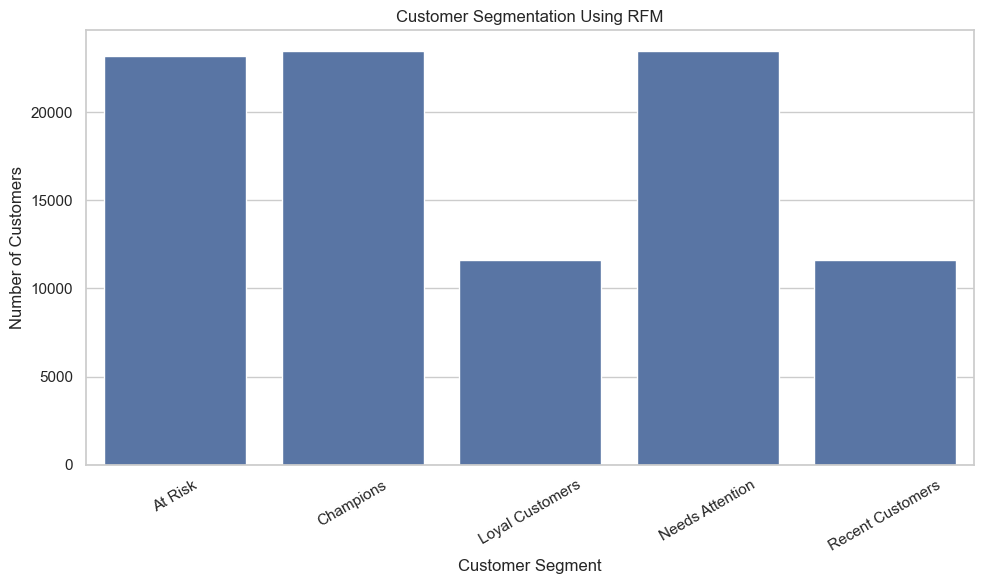

In [11]:
#  Cell 9 — Customer segmentation chart

# Create customer segment chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_summary,
    x="Segment",
    y="Total_Customers"
)

plt.title("Customer Segmentation Using RFM")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

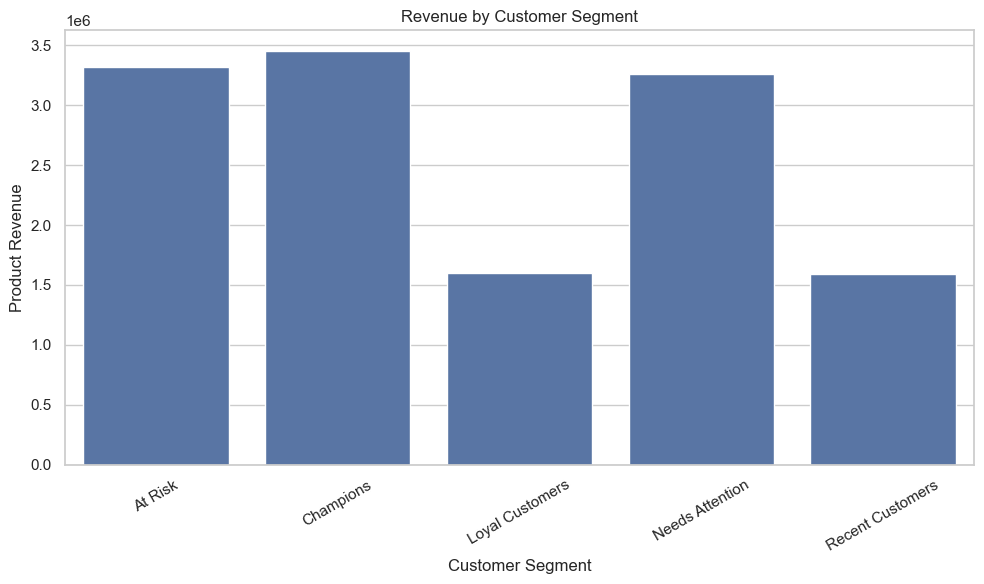

In [12]:
#  Cell 10 — Revenue by customer segment

# Create revenue comparison chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_summary,
    x="Segment",
    y="Total_Revenue"
)

plt.title("Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Product Revenue")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [13]:
# Cell 11 — Save RFM results

# Create processed folder
Path("../processed").mkdir(exist_ok=True)

# Save customer-level RFM data
rfm.to_csv(
    "../processed/customer_rfm_segments.csv",
    index=False
)

# Save segment summary
segment_summary.to_csv(
    "../processed/rfm_segment_summary.csv",
    index=False
)

print("STEP 05 COMPLETED SUCCESSFULLY!")

STEP 05 COMPLETED SUCCESSFULLY!


In [14]:
# ============================================================
# INTERVIEW EXPLANATION
# ============================================================
#
# "I used RFM analysis to understand customer purchasing behaviour.
#
# I calculated Recency, Frequency and Monetary values
# and grouped customers into different segments.
#
# This helps businesses identify valuable customers
# and improve customer retention."
#
# ============================================================
# IMPORTANT: NOTEBOOK FILE LOCATION
# ============================================================
#
# If your notebook is inside the notebooks/ folder:
#
# Use Path("../dataset") to access the dataset folder.
#
# Use Path("../processed") to access the processed folder.
#
# If your notebook is in the project root folder:
#
# Change Path("../dataset") to Path("dataset").
#
# Change Path("../processed") to Path("processed").
#
# ============================================================
# HOW TO RUN
# ============================================================
#
# Step 1: Open 05_rfm_customer_segmentation.ipynb.
#
# Step 2: Run each Python code cell in order.
#
# Step 3: Check the output after every cell.
#
# Step 4: Complete Step 05 — RFM Customer Segmentation.
#
# Step 5: Take a screenshot of your output.
#
# Step 6: Share the screenshot for review.
#
# ============================================================
# NEXT STEP
# ============================================================
#
# After completing Step 05, we will start:
#
# STEP 06 — COHORT & CUSTOMER RETENTION ANALYSIS.
#
# ============================================================
# END OF SECTION
# ============================================================